# 05 · Monitoring: Infrastructure, Data Quality and Model Quality
**AAI-540 Group 3 — CloudTrail Suspicious-Activity Classifier**

| | |
|---|---|
| **Goal** | Monitor the deployed system on three layers and show that the monitors fire when something goes wrong. |
| **Input** | Endpoint `cloudtrail-risk-endpoint` + data capture (notebook 04), training baseline (notebook 03) |
| **Output** | CloudWatch dashboard + alarms · SageMaker Model Monitor baseline, schedule and violation report · offline drift / performance report (charts below) |
| **Last step** | **Cleanup** — deletes the endpoint and monitoring schedule so they stop billing |

| layer | what we watch | tool |
|---|---|---|
| **Infrastructure** | invocations, 4xx / 5xx errors, model latency, CPU / memory | CloudWatch dashboard + alarms |
| **Data** | schema, missing values, distribution drift of each input feature vs. training | SageMaker Model Monitor (data quality) + PSI drift report |
| **Model** | score drift, alert volume vs. analyst budget, recall once (delayed) labels arrive | offline monitoring report (Section 4) |

## 1. Setup

In [1]:
%%capture pip_log
# Install the project's pinned libraries (run once per kernel, BEFORE any other import).
# The pin keeps the SageMaker Python SDK on v2, which all notebooks in this repo use.
# Output is captured to keep the notebook clean; run print(pip_log.stdout) to see it.
# (Warnings about sagemaker-core / sagemaker-mlops conflicts refer to Studio's pre-installed
#  SDK v3 packages, which this project does not use.)
%pip install -q -r ../requirements.txt

In [2]:
import os
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))   # shared project package: src/cloudtrail_mlops
DATA_DIR = Path.home() / "cloudtrail-data"           # local working copy, outside the git repo
DATA_DIR.mkdir(exist_ok=True)
os.environ["SAGEMAKER_SUPPRESS_V2_WARNING"] = "1"         # we intentionally pin SDK v2 (see requirements.txt)

import json
import time
from datetime import datetime, timedelta, timezone

import boto3
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sagemaker.model_monitor import CronExpressionGenerator, DefaultModelMonitor
from sagemaker.model_monitor.dataset_format import DatasetFormat
from sklearn.metrics import average_precision_score

from cloudtrail_mlops import aws, config, dataset, evaluation, model
from cloudtrail_mlops.plots import BLUE, MUTED, ORANGE, SERIES, setup_style

setup_style()
ctx = aws.get_context()
state = aws.load_state(ctx)
sm_client = ctx.session.sagemaker_client
cloudwatch = boto3.client("cloudwatch", region_name=ctx.region)
runtime = boto3.client("sagemaker-runtime", region_name=ctx.region)

ENDPOINT_NAME = state["endpoint_name"]
thresholds = state["thresholds"]
print(ENDPOINT_NAME, "->", sm_client.describe_endpoint(EndpointName=ENDPOINT_NAME)["EndpointStatus"])

encoder = dataset.FeatureEncoder.load(DATA_DIR / "model-input" / "encoder.json")
mart = dataset.load_mart(DATA_DIR / "features" / "feature_mart.parquet")
splits = dataset.chronological_split(mart)


def invoke(windows: pd.DataFrame) -> np.ndarray:
    payload = encoder.transform(windows).to_csv(header=False, index=False, float_format="%.6g")
    body = runtime.invoke_endpoint(EndpointName=ENDPOINT_NAME, ContentType="text/csv", Body=payload)["Body"].read().decode()
    return np.array([float(v) for v in body.replace("\n", ",").split(",") if v.strip()])

sagemaker.config INFO - Not applying SDK defaults from location: /etc/xdg/sagemaker/config.yaml
sagemaker.config INFO - Not applying SDK defaults from location: /home/sagemaker-user/.config/sagemaker/config.yaml
cloudtrail-risk-endpoint -> InService


## 2. Infrastructure monitoring — CloudWatch dashboard and alarms
SageMaker publishes endpoint metrics to CloudWatch automatically. We build one dashboard and three alarms:

| alarm | condition | why |
|---|---|---|
| `…-5xx-errors` | any 5xx error in 5 minutes | the model container is failing |
| `…-latency-p95` | p95 model latency > 200 ms for 15 minutes | alerts would arrive late |
| `…-cpu-high` | average CPU > 80 % for 15 minutes | instance too small → scale out |

In [3]:
DASHBOARD = "cloudtrail-risk-endpoint"
dimensions = ["EndpointName", ENDPOINT_NAME, "VariantName", "AllTraffic"]


def widget(x, y, title, metrics):
    return {"type": "metric", "x": x, "y": y, "width": 8, "height": 6,
            "properties": {"title": title, "region": ctx.region, "view": "timeSeries", "period": 60, "metrics": metrics}}


dashboard = {"widgets": [
    widget(0, 0, "Invocations per minute", [["AWS/SageMaker", "Invocations", *dimensions, {"stat": "Sum"}]]),
    widget(8, 0, "Errors (4XX / 5XX)", [["AWS/SageMaker", "Invocation4XXErrors", *dimensions, {"stat": "Sum"}],
                                       ["AWS/SageMaker", "Invocation5XXErrors", *dimensions, {"stat": "Sum"}]]),
    widget(16, 0, "Model latency (microseconds)", [["AWS/SageMaker", "ModelLatency", *dimensions, {"stat": "p50"}],
                                                   ["AWS/SageMaker", "ModelLatency", *dimensions, {"stat": "p95"}]]),
    widget(0, 6, "CPU utilisation (%)", [["/aws/sagemaker/Endpoints", "CPUUtilization", *dimensions, {"stat": "Average"}]]),
    widget(8, 6, "Memory utilisation (%)", [["/aws/sagemaker/Endpoints", "MemoryUtilization", *dimensions, {"stat": "Average"}]]),
    widget(16, 6, "Disk utilisation (%)", [["/aws/sagemaker/Endpoints", "DiskUtilization", *dimensions, {"stat": "Average"}]]),
]}
cloudwatch.put_dashboard(DashboardName=DASHBOARD, DashboardBody=json.dumps(dashboard))

alarm_dims = [{"Name": "EndpointName", "Value": ENDPOINT_NAME}, {"Name": "VariantName", "Value": "AllTraffic"}]
alarms = [
    dict(AlarmName=f"{ENDPOINT_NAME}-5xx-errors", Namespace="AWS/SageMaker", MetricName="Invocation5XXErrors",
         Statistic="Sum", Period=300, EvaluationPeriods=1, Threshold=0, ComparisonOperator="GreaterThanThreshold"),
    dict(AlarmName=f"{ENDPOINT_NAME}-latency-p95", Namespace="AWS/SageMaker", MetricName="ModelLatency",
         ExtendedStatistic="p95", Period=300, EvaluationPeriods=3, Threshold=200_000, ComparisonOperator="GreaterThanThreshold"),
    dict(AlarmName=f"{ENDPOINT_NAME}-cpu-high", Namespace="/aws/sagemaker/Endpoints", MetricName="CPUUtilization",
         Statistic="Average", Period=300, EvaluationPeriods=3, Threshold=80, ComparisonOperator="GreaterThanThreshold"),
]
for alarm in alarms:
    cloudwatch.put_metric_alarm(Dimensions=alarm_dims, TreatMissingData="notBreaching", **alarm)
aws.save_state(ctx, dashboard=DASHBOARD, alarms=[a["AlarmName"] for a in alarms])

print("Dashboard:", f"https://{ctx.region}.console.aws.amazon.com/cloudwatch/home?region={ctx.region}#dashboards:name={DASHBOARD}")
pd.DataFrame(cloudwatch.describe_alarms(AlarmNames=[a["AlarmName"] for a in alarms])["MetricAlarms"])[
    ["AlarmName", "MetricName", "Threshold", "ComparisonOperator", "StateValue"]]

Dashboard: https://us-east-1.console.aws.amazon.com/cloudwatch/home?region=us-east-1#dashboards:name=cloudtrail-risk-endpoint


,AlarmName,MetricName,Threshold,ComparisonOperator,StateValue
0,cloudtrail-risk-endpoint-5xx-errors,Invocation5XXErrors,0.0,GreaterThanThreshold,INSUFFICIENT_DATA
1,cloudtrail-risk-endpoint-cpu-high,CPUUtilization,80.0,GreaterThanThreshold,INSUFFICIENT_DATA
2,cloudtrail-risk-endpoint-latency-p95,ModelLatency,200000.0,GreaterThanThreshold,INSUFFICIENT_DATA


The same metrics, pulled into the notebook (traffic generated in notebook 04 and in Section 3 below):

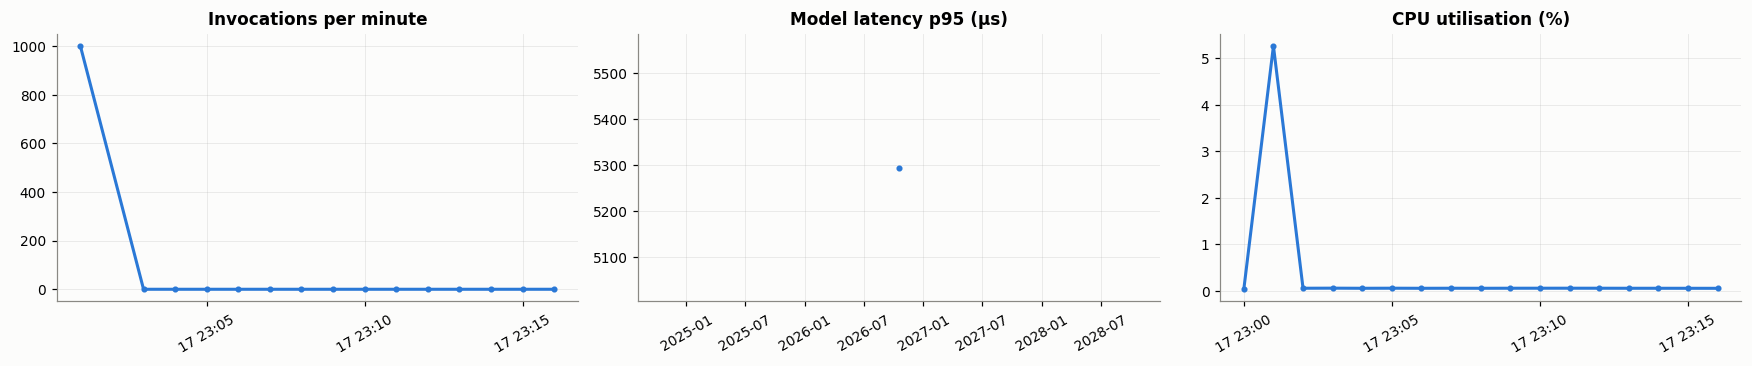

In [4]:
def endpoint_metric(namespace, name, stat, hours=3):
    end = datetime.now(timezone.utc)
    kwargs = {"ExtendedStatistics": [stat]} if stat.startswith("p") else {"Statistics": [stat]}
    points = cloudwatch.get_metric_statistics(Namespace=namespace, MetricName=name, Dimensions=alarm_dims,
                                              StartTime=end - timedelta(hours=hours), EndTime=end, Period=60, **kwargs)["Datapoints"]
    frame = pd.DataFrame(points)
    if frame.empty:
        return pd.Series(dtype=float)
    value = frame["ExtendedStatistics"].map(lambda d: d[stat]) if stat.startswith("p") else frame[stat]
    return pd.Series(value.values, index=frame["Timestamp"]).sort_index()


panels = [("AWS/SageMaker", "Invocations", "Sum", "Invocations per minute"),
          ("AWS/SageMaker", "ModelLatency", "p95", "Model latency p95 (µs)"),
          ("/aws/sagemaker/Endpoints", "CPUUtilization", "Average", "CPU utilisation (%)")]
fig, axes = plt.subplots(1, 3, figsize=(16, 3.4))
for ax, (namespace, name, stat, title) in zip(axes, panels):
    series = endpoint_metric(namespace, name, stat)
    if series.empty:
        ax.text(0.5, 0.5, "no datapoints yet\n(CloudWatch lags 1-3 min)", ha="center", va="center", transform=ax.transAxes)
    else:
        ax.plot(series.index, series.values, color=BLUE, marker="o", markersize=3)
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

## 3. Data-quality monitoring — SageMaker Model Monitor
1. **Baseline:** a processing job profiles the training features (`model-input/baseline/train_with_header.csv`) and suggests **statistics** (mean, std, distribution sketch per feature) and **constraints** (data types, completeness, value ranges).
2. **Live traffic:** every request to the endpoint is captured to S3 (enabled in notebook 04).
3. **Data-quality check:** compares the captured requests with the baseline and writes a **constraint-violations report**; violations are also published as a CloudWatch metric (section 3.2).

The baseline job takes ~5 minutes.

In [5]:
# Model Monitor runs on Apache Spark, which mis-reads column names containing "." or "=" (e.g. "last_service=s3.amazonaws.com").
# The baseline therefore uses safe positional names f000, f001, ...; captured requests have no header and are matched by position.
baseline_local = DATA_DIR / "monitoring" / "baseline_train.csv"
baseline_local.parent.mkdir(parents=True, exist_ok=True)
baseline_frame = pd.read_csv(DATA_DIR / "model-input" / "baseline" / "train_with_header.csv")
column_map = {f"f{i:03d}": name for i, name in enumerate(baseline_frame.columns)}   # safe name -> real feature name
baseline_frame.columns = list(column_map)
baseline_frame.to_csv(baseline_local, index=False)
baseline_uri = ctx.session.upload_data(str(baseline_local), bucket=ctx.bucket, key_prefix=ctx.prefix("monitoring") + "/baseline-input")

monitor = DefaultModelMonitor(role=ctx.role, instance_count=1, instance_type="ml.m5.large", volume_size_in_gb=20,
                              max_runtime_in_seconds=1800, sagemaker_session=ctx.session)
monitor.suggest_baseline(baseline_dataset=baseline_uri, dataset_format=DatasetFormat.csv(header=True),
                         output_s3_uri=ctx.s3_uri("monitoring", "baseline"), wait=True, logs=False)

baseline_stats = pd.json_normalize(monitor.baseline_statistics().body_dict["features"])
baseline_stats.insert(1, "feature", baseline_stats["name"].map(column_map))
constraints = pd.json_normalize(monitor.suggested_constraints().body_dict["features"])
constraints.insert(1, "feature", constraints["name"].map(column_map))
display(baseline_stats[["name", "feature", "inferred_type", "numerical_statistics.mean", "numerical_statistics.std_dev",
                        "numerical_statistics.min", "numerical_statistics.max"]].head(10).round(3))
constraints.head(10)

INFO:sagemaker:Creating processing-job with name baseline-suggestion-job-2026-10-17-23-17-38-752


.........................................................................................!

,name,feature,inferred_type,numerical_statistics.mean,numerical_statistics.std_dev,numerical_statistics.min,numerical_statistics.max
0,f000,distinct_services,Fractional,1.187,1.188,1.0,84.0
1,f001,distinct_apis,Fractional,1.546,3.932,1.0,260.0
2,f002,distinct_regions,Fractional,1.270,1.531,1.0,16.0
3,f003,distinct_source_ips,Fractional,1.032,0.232,1.0,11.0
4,f004,distinct_ua_families,Fractional,1.012,0.118,1.0,3.0
5,f005,error_count,Fractional,1.455,17.546,0.0,1136.0
6,f006,auth_error_count,Fractional,1.112,16.434,0.0,1136.0
7,f007,write_count,Fractional,0.431,6.916,0.0,522.0
8,f008,read_only_known_count,Fractional,0.188,4.210,0.0,297.0
9,f009,read_only_coverage_current,Fractional,0.014,0.103,0.0,1.0


,name,feature,inferred_type,completeness,num_constraints.is_non_negative
0,f000,distinct_services,Fractional,1.0,True
1,f001,distinct_apis,Fractional,1.0,True
2,f002,distinct_regions,Fractional,1.0,True
3,f003,distinct_source_ips,Fractional,1.0,True
4,f004,distinct_ua_families,Fractional,1.0,True
5,f005,error_count,Fractional,1.0,True
6,f006,auth_error_count,Fractional,1.0,True
7,f007,write_count,Fractional,1.0,True
8,f008,read_only_known_count,Fractional,1.0,True
9,f009,read_only_coverage_current,Fractional,1.0,True


### 3.1 Send normal and **drifted** traffic
To prove the monitor works we send two kinds of traffic:
* **normal** — real 2020 windows;
* **drifted** — the same windows with activity counts multiplied by 6 and an AWS region the model has never seen. This imitates an upstream change (e.g. a new automation tool or a log-format change) that should trigger violations.

In [6]:
normal_traffic = splits["test"].sample(1500, random_state=11)
drifted_traffic = splits["test"].sample(500, random_state=12).copy()
for column in ("distinct_apis", "error_count", "auth_error_count", "write_count", "prior_writes_24h", "distinct_source_ips"):
    drifted_traffic[column] = drifted_traffic[column].fillna(0) * 6
drifted_traffic["last_region"] = "ap-unseen-1"

# one window per request: each captured request is then exactly one record for Model Monitor
normal_scores = np.concatenate([invoke(normal_traffic.iloc[[i]]) for i in range(len(normal_traffic))])
drifted_scores = np.concatenate([invoke(drifted_traffic.iloc[[i]]) for i in range(len(drifted_traffic))])
print(f"normal traffic : {len(normal_scores)} windows | alert rate {np.mean(normal_scores >= thresholds['medium']):.1%}")
print(f"drifted traffic: {len(drifted_scores)} windows | alert rate {np.mean(drifted_scores >= thresholds['medium']):.1%}")
print("Waiting 3 minutes for data capture files to land in S3 ...")
time.sleep(180)

normal traffic : 1500 windows | alert rate 5.9%
drifted traffic: 500 windows | alert rate 22.6%
Waiting 3 minutes for data capture files to land in S3 ...


### 3.2 Run the data-quality check on the captured traffic
SageMaker Model Monitor's *scheduled* executions are in **maintenance mode and cannot be created by new AWS accounts** (`CreateDataQualityJobDefinition` is rejected), and Learner Lab accounts count as new. We therefore keep Model Monitor's **baseline** (statistics and constraints from section 3) and run the same comparison ourselves on the traffic the endpoint captured to S3:

| check | violation when | Model Monitor equivalent |
|---|---|---|
| completeness | any missing value in a feature | `completeness_check` |
| range | > 1 % of values outside the min–max seen in training | constraint on `numerical_statistics` |
| distribution drift | PSI ≥ 0.25 against the training distribution | `baseline_drift_check` |

The result is written to S3 (`monitoring/reports/`) and published as the CloudWatch metric `CloudTrailRiskModel / DataQualityViolations`, so an alarm can page the on-call engineer exactly as a Model Monitor schedule would.

In [8]:
# Load the requests and responses the endpoint captured to S3 during the last two hours.
import base64
import io


def decode(payload):
    return base64.b64decode(payload["data"]).decode() if payload.get("encoding") == "BASE64" else payload["data"]


s3 = boto3.client("s3")
capture_prefix = f"{ctx.prefix('datacapture')}/{ENDPOINT_NAME}/"
since = datetime.now(timezone.utc) - timedelta(hours=2)
records = []
for page in s3.get_paginator("list_objects_v2").paginate(Bucket=ctx.bucket, Prefix=capture_prefix):
    for obj in page.get("Contents", []):
        if obj["LastModified"] < since:
            continue
        for line in s3.get_object(Bucket=ctx.bucket, Key=obj["Key"])["Body"].read().decode().splitlines():
            event = json.loads(line)
            rows = decode(event["captureData"]["endpointInput"]).strip().splitlines()
            scores = decode(event["captureData"]["endpointOutput"]).replace("\n", ",").split(",")
            for row, score in zip(rows, [s for s in scores if s.strip()]):
                records.append({"time": event["eventMetadata"]["inferenceTime"], "row": row, "score": float(score)})

captured = pd.DataFrame(records).sort_values("time", kind="stable").reset_index(drop=True)
captured_features = pd.read_csv(io.StringIO("\n".join(captured["row"])), header=None, names=encoder.feature_names)
# the drifted requests were sent last (section 3.1)
captured["traffic"] = "normal"
captured.loc[captured.index[-len(drifted_traffic):], "traffic"] = "drifted"
print(f"Captured records in the last 2 hours: {len(captured):,} "
      f"({(captured.traffic == 'normal').sum():,} normal, {(captured.traffic == 'drifted').sum():,} drifted)")
captured.groupby("traffic")["score"].describe().round(4)

Captured records in the last 2 hours: 3,010 (2,510 normal, 500 drifted)


,count,mean,std,min,25%,50%,75%,max
traffic,,,,,,,,
drifted,500.0,0.3260,0.0227,0.3084,0.3140,0.3147,0.333,0.5083
normal,2510.0,0.3131,0.0192,0.3068,0.3068,0.3070,0.311,0.6774


In [9]:
# Compare captured traffic with the Model Monitor baseline (training-data statistics).
stats = baseline_stats.set_index("feature")
# Requests carry values rounded to 6 significant digits, so the reference goes through the same CSV formatting.
train_reference = pd.read_csv(io.StringIO(encoder.transform(splits["train"]).to_csv(header=False, index=False, float_format="%.6g")),
                              header=None, names=encoder.feature_names)


def data_quality_report(current: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for feature in encoder.feature_names:
        values = current[feature]
        low, high = stats.loc[feature, "numerical_statistics.min"], stats.loc[feature, "numerical_statistics.max"]
        missing = float(values.isna().mean())
        tolerance = 1e-5 * max(1.0, abs(low), abs(high))          # ignore rounding differences
        out_of_range = float(((values < low - tolerance) | (values > high + tolerance)).mean())
        drift = evaluation.psi(train_reference[feature].to_numpy(), values.to_numpy())
        if missing > 0:
            rows.append((feature, "completeness_check", f"{missing:.1%} missing values (baseline: none)"))
        if out_of_range > 0.01:
            rows.append((feature, "range_check", f"{out_of_range:.1%} of values outside the training range [{low:g}, {high:g}]"))
        if drift >= evaluation.PSI_ALERT:
            rows.append((feature, "baseline_drift_check", f"PSI {drift:.2f} vs training distribution (alert at {evaluation.PSI_ALERT})"))
    return pd.DataFrame(rows, columns=["feature", "constraint_check_type", "description"])


reports = {name: data_quality_report(captured_features[captured.traffic == name]) for name in ("normal", "drifted")}
for name, report in reports.items():
    print(f"{name} traffic: {len(report)} constraint violations")
display(reports["normal"] if len(reports["normal"]) else pd.DataFrame({"normal traffic": ["no violations"]}))
reports["drifted"]

normal traffic: 2 constraint violations
drifted traffic: 6 constraint violations


,feature,constraint_check_type,description
0,prior_ip_mass_24h,baseline_drift_check,PSI 0.32 vs training distribution (alert at 0.25)
1,prior_active_windows_24h,baseline_drift_check,PSI 0.32 vs training distribution (alert at 0.25)


,feature,constraint_check_type,description
0,distinct_apis,baseline_drift_check,PSI 9.29 vs training distribution (alert at 0.25)
1,distinct_source_ips,range_check,"4.0% of values outside the training range [1, 11]"
2,prior_ip_mass_24h,baseline_drift_check,PSI 0.28 vs training distribution (alert at 0.25)
3,prior_active_windows_24h,baseline_drift_check,PSI 0.30 vs training distribution (alert at 0.25)
4,last_region=us-east-1,baseline_drift_check,PSI 0.95 vs training distribution (alert at 0.25)
5,last_region=us-west-2,baseline_drift_check,PSI 9.25 vs training distribution (alert at 0.25)


In [10]:
# Store the report as monitoring evidence and publish the violation counts to CloudWatch.
run_time = datetime.now(timezone.utc)
report_key = f"{ctx.prefix('monitoring')}/reports/data-quality-{run_time:%Y%m%dT%H%M%SZ}.json"
s3.put_object(Bucket=ctx.bucket, Key=report_key, Body=json.dumps(
    {"endpoint": ENDPOINT_NAME, "run_time": run_time.isoformat(), "records": int(len(captured)),
     "violations": {name: report.to_dict("records") for name, report in reports.items()}}, indent=2).encode())

cloudwatch.put_metric_data(Namespace="CloudTrailRiskModel", MetricData=[
    {"MetricName": "DataQualityViolations", "Dimensions": [{"Name": "EndpointName", "Value": ENDPOINT_NAME},
                                                            {"Name": "Traffic", "Value": name}],
     "Value": float(len(report)), "Unit": "Count"} for name, report in reports.items()])
cloudwatch.put_metric_alarm(
    AlarmName=f"{ENDPOINT_NAME}-data-quality", Namespace="CloudTrailRiskModel", MetricName="DataQualityViolations",
    Dimensions=[{"Name": "EndpointName", "Value": ENDPOINT_NAME}, {"Name": "Traffic", "Value": "drifted"}],
    Statistic="Maximum", Period=300, EvaluationPeriods=1, Threshold=5, ComparisonOperator="GreaterThanOrEqualToThreshold",
    TreatMissingData="notBreaching")
aws.save_state(ctx, alarms=state.get("alarms", []) + [f"{ENDPOINT_NAME}-data-quality"], data_quality_report=f"s3://{ctx.bucket}/{report_key}")
print("Report:", f"s3://{ctx.bucket}/{report_key}")
print("CloudWatch metric CloudTrailRiskModel/DataQualityViolations published; alarm fires at >= 5 violations")

Report: s3://sagemaker-us-east-1-674905628044/cloudtrail-mlops/monitoring/reports/data-quality-20261017T233755Z.json
CloudWatch metric CloudTrailRiskModel/DataQualityViolations published; alarm fires at >= 5 violations


**Reading the report (this run, 3,010 captured records).**
* **Drifted traffic: 6 violations** — `distinct_apis` (PSI 9.3), the region one-hot columns (the never-seen region moves every request into `last_region=__other__`, PSI 0.95–9.3) and `distinct_source_ips` outside the training range. The model also reacts: its MEDIUM alert rate jumps from **5.9 % to 22.6 %**. This exceeds the alarm threshold of 5 violations, so the `cloudtrail-risk-endpoint-data-quality` alarm would page the on-call engineer.
* **Normal 2020 traffic: 2 violations, both genuine** — `prior_ip_mass_24h` and `prior_active_windows_24h` (PSI 0.32). These rolling-history features really have shifted since the 2017–18 training period (see the monthly drift heat-map below); they are below the 5-violation alarm threshold but are the first candidates to watch or replace with relative versions.

In production the alarm triggers an investigation of the upstream change and, if the change is genuine, **retraining through the CI/CD pipeline** (notebook 06).

## 4. Model and data monitoring report (offline, with delayed labels)
Model Monitor checks inputs. To monitor the **model** we also need its outputs and, once analysts have reviewed alerts, the labels. Here we replay the 2020 test year month by month as if it were production traffic and track:
* **feature drift** — Population Stability Index (PSI) of every input vs. the training period (< 0.10 stable, 0.10–0.25 warn, > 0.25 alert);
* **prediction drift** — PSI of the risk-score distribution vs. the validation year, and the daily alert volume vs. the analyst budget;
* **performance with delayed labels** — monthly recall and average precision.

In [11]:
local_dir = DATA_DIR / "model"
booster = model.load_booster(local_dir / "xgboost-model")
train_encoded = encoder.transform(splits["train"])
validation_scores = model.predict(booster, encoder.transform(splits["validation"]))
test = splits["test"].copy()
test["score"] = model.predict(booster, encoder.transform(test))
test["month"] = test.window_start.dt.strftime("%Y-%m")

rows, psi_matrix = [], {}
for month, frame in test.groupby("month"):
    drift = evaluation.drift_report(train_encoded, encoder.transform(frame), config.NUMERIC_FEATURES)
    psi_matrix[month] = drift.set_index("feature")["psi"]
    y = frame[config.TARGET_COLUMN].to_numpy()
    alerts = frame.score >= thresholds["medium"]
    rows.append({"month": month, "windows": len(frame), "features_warn": int((drift.status == "WARN").sum()),
                 "features_alert": int((drift.status == "ALERT").sum()),
                 "score_psi": round(evaluation.psi(validation_scores, frame.score.to_numpy()), 3),
                 "alerts_per_day": round(alerts.sum() / evaluation.days_covered(frame.window_start), 2),
                 "suspicious": int(y.sum()),
                 "recall": round(alerts[y == 1].mean(), 3) if y.sum() else np.nan,
                 "average_precision": round(average_precision_score(y, frame.score), 3) if 0 < y.sum() < len(y) else np.nan})
monthly = pd.DataFrame(rows)
monthly

,month,windows,features_warn,features_alert,score_psi,alerts_per_day,suspicious,recall,average_precision
0,2020-01,1750,1,2,0.061,3.49,15,0.267,0.204
1,2020-02,1878,0,2,0.170,2.14,0,NaN,NaN
2,2020-03,2423,2,3,0.247,3.42,2,1.000,0.185
3,2020-04,2063,2,2,0.133,3.64,17,0.235,0.070
4,2020-05,1904,0,2,0.129,2.42,2,1.000,0.611
5,2020-06,1769,0,2,0.076,2.47,1,1.000,0.023
6,2020-07,1932,0,2,0.100,2.81,2,1.000,0.146
7,2020-08,1709,0,3,0.134,2.94,22,1.000,0.764
8,2020-09,1957,1,2,0.042,4.88,33,0.970,0.550
9,2020-10,523,7,1,0.199,16.67,7,1.000,0.725


INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


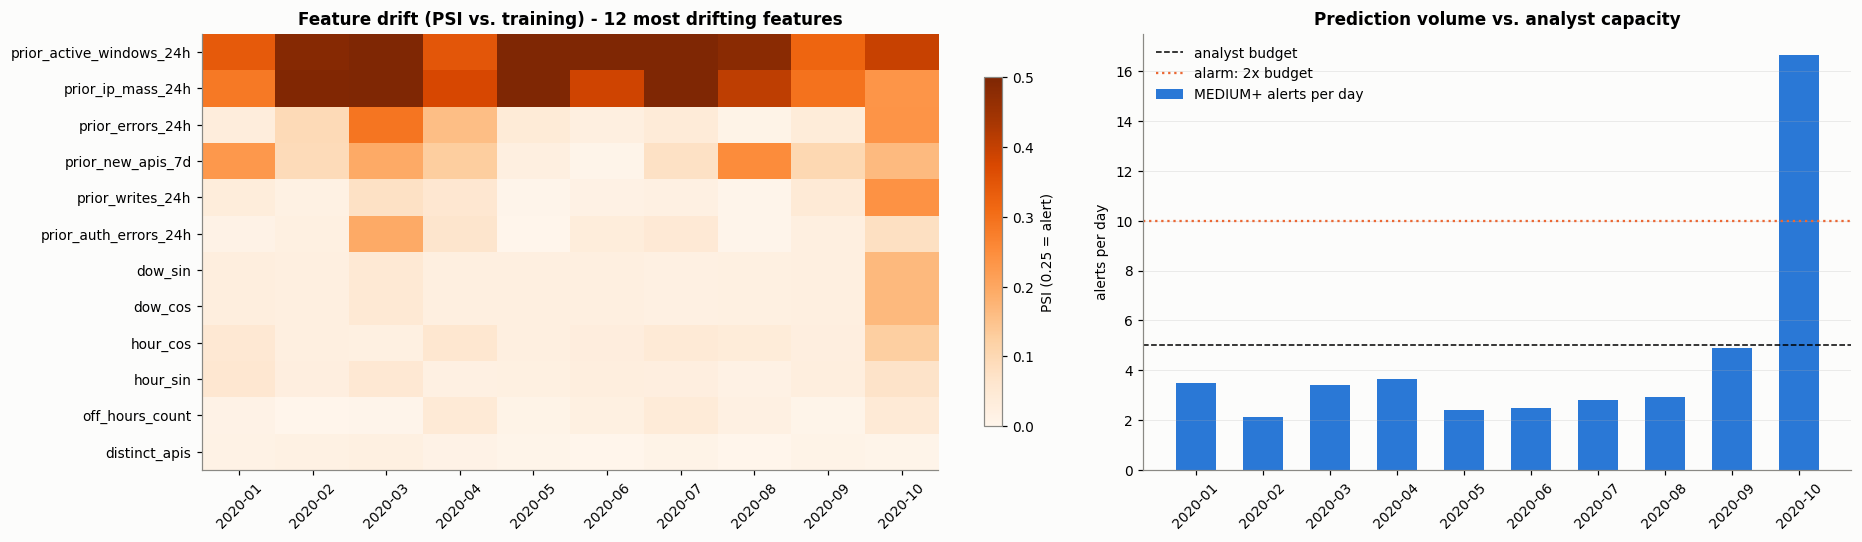

In [12]:
psi_table = pd.DataFrame(psi_matrix)
top_features = psi_table.max(axis=1).sort_values(ascending=False).head(12).index
fig, axes = plt.subplots(1, 2, figsize=(17, 5), gridspec_kw={"width_ratios": [1.3, 1]})
image = axes[0].imshow(psi_table.loc[top_features], cmap="Oranges", vmin=0, vmax=0.5, aspect="auto")
axes[0].set_xticks(range(psi_table.shape[1]), psi_table.columns, rotation=45)
axes[0].set_yticks(range(len(top_features)), top_features)
axes[0].grid(False)
axes[0].set_title("Feature drift (PSI vs. training) - 12 most drifting features")
fig.colorbar(image, ax=axes[0], shrink=0.8, label="PSI (0.25 = alert)")

axes[1].bar(monthly.month, monthly.alerts_per_day, color=BLUE, width=0.6, label="MEDIUM+ alerts per day")
axes[1].axhline(config.MEDIUM_ALERTS_PER_DAY, color="black", ls="--", lw=1, label="analyst budget")
axes[1].axhline(2 * config.MEDIUM_ALERTS_PER_DAY, color=ORANGE, ls=":", lw=1.5, label="alarm: 2x budget")
axes[1].set(title="Prediction volume vs. analyst capacity", ylabel="alerts per day")
axes[1].tick_params(axis="x", rotation=45)
axes[1].grid(axis="x", visible=False)
axes[1].legend()
plt.tight_layout()
plt.show()

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should

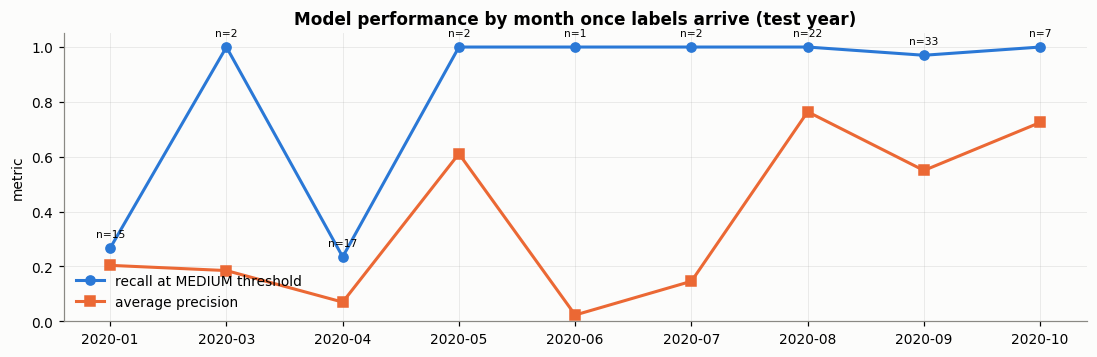

In [13]:
fig, ax = plt.subplots(figsize=(12, 3.4))
known = monthly.dropna(subset=["recall"])
ax.plot(known.month, known.recall, "o-", color=BLUE, label="recall at MEDIUM threshold")
ax.plot(known.month, known.average_precision, "s-", color=ORANGE, label="average precision")
ax.set(title="Model performance by month once labels arrive (test year)", ylim=(0, 1.05), ylabel="metric")
for _, row in known.iterrows():
    ax.annotate(f"n={row.suspicious}", (row.month, row.recall), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=7)
ax.legend(loc="lower left")
plt.show()

**Observations (2020 replayed month by month).**
* **Feature drift:** two features are in ALERT every month — `prior_active_windows_24h` and `prior_ip_mass_24h` (actors are active in more windows and from more IPs per day than in 2017–18). All other inputs stay mostly stable; October 2020 shows broader drift (calendar and 24-hour history features), driven by the short 7-day month and one very active actor.
* **Prediction drift:** score PSI stays below 0.25 every month (max 0.25 in March), and alert volume stays **within the 5/day analyst budget for nine months** — until **October 2020 (16.7 alerts/day)**, which breaches the 2× budget alarm. That is exactly the signal that should trigger a threshold review and retraining.
* **Delayed-label performance:** recall at MEDIUM is ≥ 97 % in 7 of 9 months with positives, but drops to **27 % (Jan) and 24 % (Apr)**. Combined with the drift above, the monitoring plan below would have flagged the model for retraining in spring 2020.

### 4.1 Monitoring plan (what fires, and what we do)

In [14]:
pd.DataFrame([
    ("Infrastructure", "5xx errors / p95 latency / CPU", "> 0 errors in 5 min; p95 > 200 ms or CPU > 80 % for 15 min", "CloudWatch alarm -> on-call; scale out or roll back"),
    ("Data quality", "schema, completeness, ranges (Model Monitor)", "any constraint violation in an hourly run", "inspect upstream log change; block retraining on bad data"),
    ("Data drift", "PSI per input feature vs. training", "PSI > 0.25 on >= 5 features", "investigate; trigger retraining pipeline"),
    ("Prediction drift", "score PSI vs. validation; alerts per day", "score PSI > 0.25 or alerts > 2x analyst budget", "re-check thresholds; analyst review"),
    ("Model quality", "monthly recall / AP on analyst-reviewed alerts", "recall < 50 % or AP lift < 5x for 2 months", "retrain via CI/CD pipeline; manual approval before deploy"),
], columns=["layer", "metric", "threshold", "action"])

,layer,metric,threshold,action
0,Infrastructure,5xx errors / p95 latency / CPU,> 0 errors in 5 min; p95 > 200 ms or CPU > 80 ...,CloudWatch alarm -> on-call; scale out or roll...
1,Data quality,"schema, completeness, ranges (Model Monitor)",any constraint violation in an hourly run,inspect upstream log change; block retraining ...
2,Data drift,PSI per input feature vs. training,PSI > 0.25 on >= 5 features,investigate; trigger retraining pipeline
3,Prediction drift,score PSI vs. validation; alerts per day,score PSI > 0.25 or alerts > 2x analyst budget,re-check thresholds; analyst review
4,Model quality,monthly recall / AP on analyst-reviewed alerts,recall < 50 % or AP lift < 5x for 2 months,retrain via CI/CD pipeline; manual approval be...


## 5. Cleanup — stop everything that bills by the hour
Run this after recording the video demo. It deletes the monitoring schedule, the endpoint, its configuration and model. The S3 data, the Model Registry versions, the CloudWatch dashboard and the feature group are kept as evidence for the submission (they cost nothing or cents). Set `DELETE_FEATURE_GROUP = True` at the very end of the project.

In [15]:
CLEANUP = False               # <- set True when you are done with the demo
DELETE_FEATURE_GROUP = False  # <- set True at the very end of the project

if CLEANUP:
    if state.get("monitoring_schedule"):
        try:
            sm_client.delete_monitoring_schedule(MonitoringScheduleName=state["monitoring_schedule"])
            print("deleted monitoring schedule")
            time.sleep(30)
        except sm_client.exceptions.ResourceNotFound:
            pass
    try:
        config_name = sm_client.describe_endpoint(EndpointName=ENDPOINT_NAME)["EndpointConfigName"]
        model_names = [v["ModelName"] for v in sm_client.describe_endpoint_config(EndpointConfigName=config_name)["ProductionVariants"]]
        sm_client.delete_endpoint(EndpointName=ENDPOINT_NAME)
        sm_client.delete_endpoint_config(EndpointConfigName=config_name)
        for name in model_names:
            sm_client.delete_model(ModelName=name)
        print("deleted endpoint, endpoint config and model")
    except sm_client.exceptions.ClientError as error:
        print("endpoint already deleted:", error)
    if DELETE_FEATURE_GROUP and state.get("feature_group"):
        sm_client.delete_feature_group(FeatureGroupName=state["feature_group"])
        print("deleted feature group")
    print("Remaining endpoints:", [e["EndpointName"] for e in sm_client.list_endpoints()["Endpoints"]])

## 6. Summary
* **Infrastructure:** CloudWatch dashboard `cloudtrail-risk-endpoint` (invocations, 4xx/5xx errors, latency p50/p95, CPU / memory / disk) and three alarms (5xx errors, p95 latency, CPU).
* **Data quality:** Model Monitor baseline (statistics + constraints for all 70 encoded inputs) and a data-quality check of 3,010 captured endpoint requests against it — **2 violations for normal traffic vs 6 for drifted traffic**, saved to S3 and published as a CloudWatch metric with an alarm. (Scheduled Model Monitor executions are unavailable to new AWS accounts, so the comparison runs in the notebook.)
* **Model quality:** monthly feature-drift, prediction-drift and delayed-label report for 2020: two persistently drifting history features, alert volume within budget until October 2020, and recall dips in January and April — each mapped to a threshold and an action in the monitoring plan.
* Remember to run the **cleanup cell** (`CLEANUP = True`) after recording the demo.